Pdf and cdf of a simple continuous RV (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $f(x)$, $F(t)$ | `f`, `F` | pdf and cdf |
| $x_\omega$, $S$ | `x_omega`, `S` | realizations and their number |
| $\Delta x$ | `dx` | discretization (bin) size |
| $\hat{f}$, $\hat{F}$ | `f_hat`, `F_hat` | discrete (empirical) approximations |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

Pdf $f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}$ and cdf
$F(t)=\frac{1}{2}\left(1+\mathrm{erf}(t/\sqrt{2})\right)$.

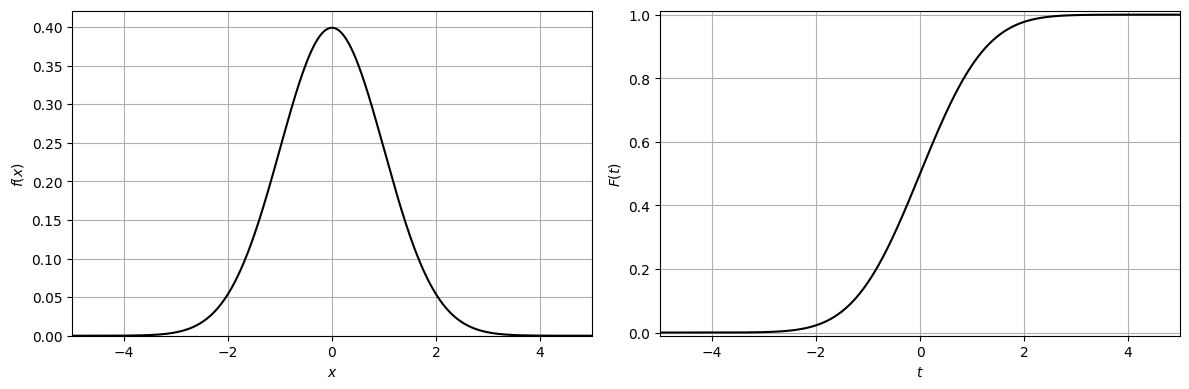

In [2]:
x = np.linspace(-5, 5, 1000)
f = norm.pdf(x, 0, 1)
t = x
F = norm.cdf(t, 0, 1)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(x, f, 'black', linewidth=1.5)
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$f(x)$')
axs[0].axis([-5, 5, 0, 0.42])
axs[0].grid(True)
axs[1].plot(t, F, 'black', linewidth=1.5)
axs[1].set_xlabel('$t$')
axs[1].set_ylabel('$F(t)$')
axs[1].axis([-5, 5, -0.01, 1.01])
axs[1].grid(True)
plt.tight_layout()
plt.show()

Discrete approximations with $\Delta x=0.5$ built from $S=1000$ realizations $x_\omega$:
$\hat{f}(x)\approx\frac{\hat{F}(x+\Delta x)-\hat{F}(x)}{\Delta x}$ (histogram) and
$\hat{F}(t)=\frac{1}{S}\sum_{\omega}\mathbf{1}[x_\omega\leq t]$.

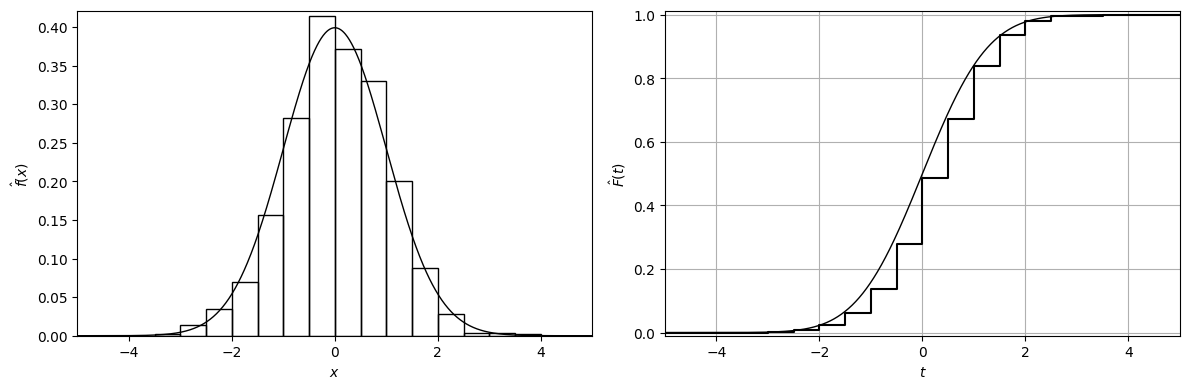

In [3]:
np.random.seed(1)  # reproducibility
S = 1000
x_omega = np.random.normal(0, 1, S)
dx = 0.5
t_grid = np.arange(-5, 5 + dx, dx)

F_hat = np.zeros(len(t_grid))
for i in range(len(t_grid)):
    for w in range(S):
        if x_omega[w] <= t_grid[i]:          # indicator 1[x_omega <= t]
            F_hat[i] += 1
F_hat = F_hat / S

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(x_omega, bins=t_grid, density=True, edgecolor='black', facecolor='none', linewidth=1)
axs[0].plot(x, f, 'k-', linewidth=1)
axs[0].set_xlabel('$x$')
axs[0].set_ylabel(r'$\hat{f}(x)$')
axs[0].axis([-5, 5, 0, 0.42])
axs[1].step(t_grid, F_hat, color='black', where='post')
axs[1].plot(t, F, 'k-', linewidth=1)
axs[1].set_xlabel('$t$')
axs[1].set_ylabel(r'$\hat{F}(t)$')
axs[1].axis([-5, 5, -0.01, 1.01])
axs[1].grid(True)
plt.tight_layout()
plt.show()